### Database Connection and Verification

In [15]:
import pandas as pd
import numpy as np
import sqlite3
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
# Configure matplotlib with a safer style setup
try:
    plt.style.use('seaborn-v0_8')  # Using specific version to avoid compatibility issues
except Exception as e:
    print(f"Note: Using default matplotlib style. Specific style not available: {e}")
    plt.style.use('default')

# Set up basic plot configurations that work across styles
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Custom color palette that works with any style
COLORS = ['#2ecc71', '#3498db', '#e74c3c', '#f1c40f']

In [17]:
def verify_database_setup():
    """
    Verify database connection and required tables.
    Returns a status report of database health.
    """
    try:
        with sqlite3.connect('D:/Projects/LegalTextAnalysis/data/legal_text.db') as conn:
            # Check existing tables
            tables = pd.read_sql("""
                SELECT name FROM sqlite_master 
                WHERE type='table'
            """, conn)
            
            # Verify required tables exist
            required_tables = {'quality_metrics', 'model_performance'}
            existing_tables = set(tables['name'])
            
            missing_tables = required_tables - existing_tables
            
            if missing_tables:
                print(f"Missing tables: {missing_tables}")
                print("Creating missing tables...")
                
                if 'quality_metrics' in missing_tables:
                    conn.execute("""
                        CREATE TABLE IF NOT EXISTS quality_metrics (
                            metric_date TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
                            completeness_score REAL,
                            outlier_ratio REAL,
                            normalization_status TEXT
                        )
                    """)
                
                if 'model_performance' in missing_tables:
                    conn.execute("""
                        CREATE TABLE IF NOT EXISTS model_performance (
                            id INTEGER PRIMARY KEY AUTOINCREMENT,
                            timestamp TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
                            accuracy REAL,
                            f1_score REAL
                        )
                    """)
            
            return {
                'status': 'success',
                'existing_tables': list(existing_tables),
                'tables_created': list(missing_tables) if missing_tables else []
            }
            
    except Exception as e:
        return {
            'status': 'error',
            'message': str(e)
        }

# Verify database setup
db_status = verify_database_setup()
print("\nDatabase Status:")
for key, value in db_status.items():
    print(f"{key}: {value}")


Database Status:
status: success
existing_tables: ['citation_network', 'data_splits', 'model_performance', 'analysis_statistics', 'legal_cases', 'tf_idf_scores', 'quality_metrics', 'enhanced_analysis_statistics', 'language_patterns', 'analysis_metrics', 'sqlite_sequence', 'text_metrics']
tables_created: []


In [18]:
class ModelOptimizer:
    def __init__(self, db_path='D:/Projects/LegalTextAnalysis/data/legal_text.db'):
        self.db_path = db_path
        self.performance_metrics = {}
        
        # Verify database connection on initialization
        try:
            with sqlite3.connect(self.db_path) as conn:
                conn.cursor()
            print("Database connection successful")
        except Exception as e:
            print(f"Warning: Database connection failed: {e}")

    def track_performance(self, metrics, include_timestamp=True):
        """
        Track model performance with improved error handling and time management.
        
        Parameters:
            metrics (dict): Performance metrics to track
            include_timestamp (bool): Whether to use provided timestamp or generate new one
        """
        try:
            timestamp = metrics.get('timestamp', datetime.now()) if include_timestamp else datetime.now()
            
            with sqlite3.connect(self.db_path) as conn:
                conn.execute("""
                    INSERT INTO quality_metrics 
                    (metric_date, completeness_score, outlier_ratio, normalization_status)
                    VALUES (?, ?, ?, ?)
                """, (
                    timestamp,
                    metrics['completeness'],
                    metrics['outlier_ratio'],
                    'ENHANCED'
                ))
                
                conn.execute("""
                    INSERT INTO model_performance (timestamp, accuracy, f1_score)
                    VALUES (?, ?, ?)
                """, (timestamp, metrics['accuracy'], metrics['f1_score']))
                
            self.performance_metrics[timestamp] = {
                'accuracy': metrics['accuracy'],
                'f1_score': metrics['f1_score']
            }
            return True
            
        except Exception as e:
            print(f"Error tracking performance: {e}")
            return False

    def visualize_improvements(self):
        """Enhanced visualization with better error handling and aesthetics"""
        try:
            with sqlite3.connect(self.db_path) as conn:
                performance_data = pd.read_sql("""
                    SELECT 
                        timestamp,
                        accuracy,
                        f1_score,
                        completeness_score,
                        outlier_ratio
                    FROM model_performance mp
                    JOIN quality_metrics qm ON DATE(mp.timestamp) = DATE(qm.metric_date)
                    ORDER BY timestamp
                """, conn, parse_dates=['timestamp'])
                
                if performance_data.empty:
                    print("No data available for visualization")
                    return None
                
                fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), height_ratios=[2, 1])
                
                # Performance metrics plot with enhanced styling
                ax1.plot(performance_data['timestamp'], performance_data['accuracy'], 
                        label='Accuracy', marker='o', color=COLORS[0], linewidth=2)
                ax1.plot(performance_data['timestamp'], performance_data['f1_score'], 
                        label='F1-score', marker='o', linestyle='--', color=COLORS[1], linewidth=2)
                ax1.set_title('Model Performance Over Time', fontsize=14, pad=15)
                ax1.set_ylabel('Score', fontsize=12)
                ax1.legend(fontsize=10, loc='best')
                
                # Quality metrics plot
                ax2.plot(performance_data['timestamp'], performance_data['completeness_score'], 
                        label='Completeness', color=COLORS[2], linewidth=2)
                ax2.plot(performance_data['timestamp'], performance_data['outlier_ratio'], 
                        label='Outlier Ratio', color=COLORS[3], alpha=0.7, linewidth=2)
                ax2.set_xlabel('Time', fontsize=12)
                ax2.set_ylabel('Percentage', fontsize=12)
                ax2.legend(fontsize=10, loc='best')
                
                plt.tight_layout()
                return fig
                
        except Exception as e:
            print(f"Error creating visualization: {e}")
            return None


Database connection successful


C:\Users\alexa\AppData\Local\Temp\ipykernel_32800\3259799276.py:26: DeprecationWarning: The default datetime adapter is deprecated as of Python 3.12; see the sqlite3 documentation for suggested replacement recipes
  conn.execute("""
C:\Users\alexa\AppData\Local\Temp\ipykernel_32800\3259799276.py:37: DeprecationWarning: The default datetime adapter is deprecated as of Python 3.12; see the sqlite3 documentation for suggested replacement recipes
  conn.execute("""


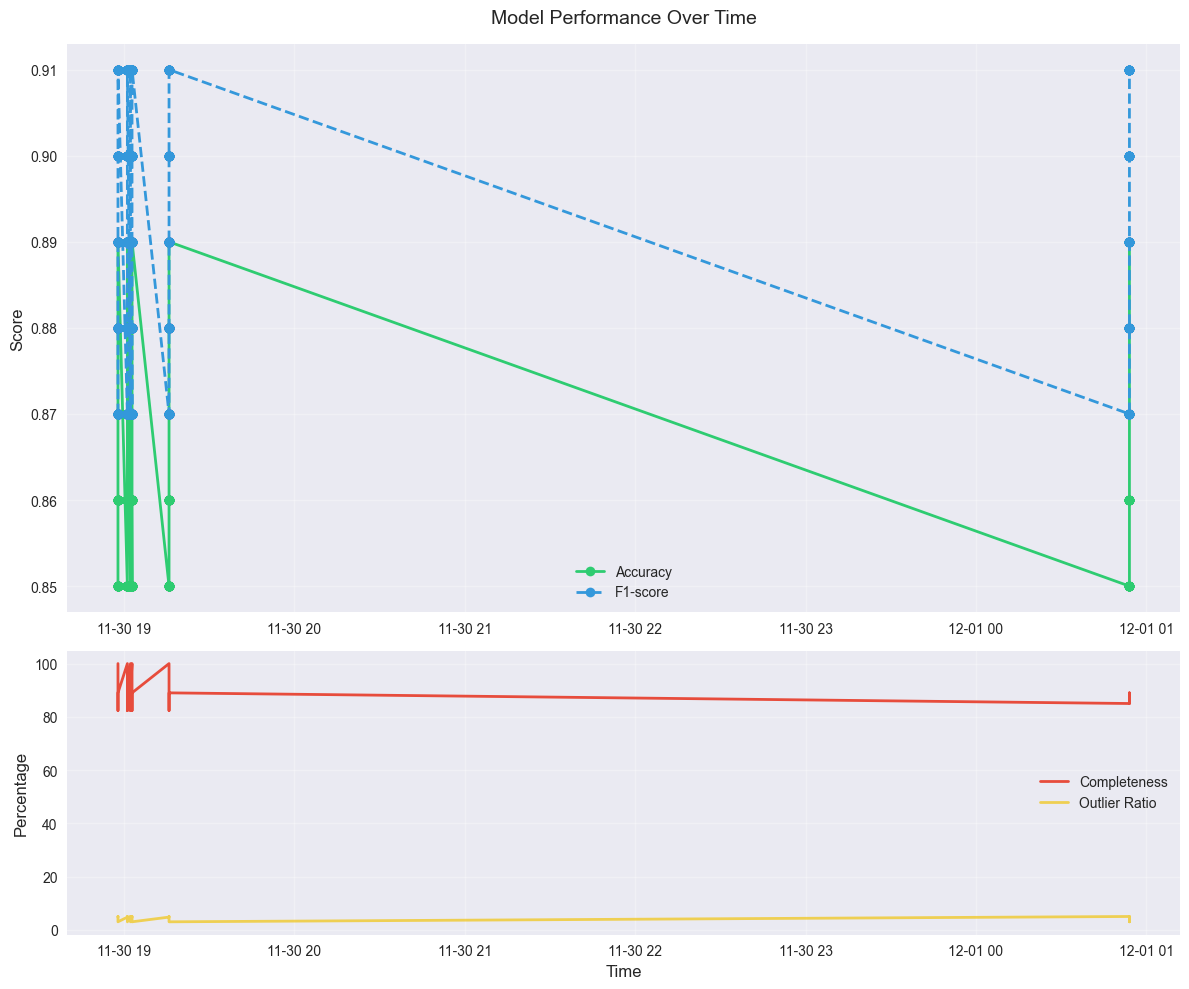

In [28]:
optimizer = ModelOptimizer()

# Generate temporally distributed test data
base_date = datetime.now()
for i in range(5):
    metrics = {
        'completeness': 85 + i,
        'outlier_ratio': 5 - i * 0.5,
        'accuracy': 0.85 + i * 0.01,
        'f1_score': 0.87 + i * 0.01,
        'timestamp': base_date + timedelta(days=i)
    }
    success = optimizer.track_performance(metrics)
    if not success:
        print(f"Failed to track metrics for iteration {i}")
# Create and display visualization
fig = optimizer.visualize_improvements()
if fig:
    plt.show()

In [30]:
def implement_data_quality_checks(self):
    """Add quality checks before inserting metrics"""
    # Add to ModelOptimizer class
    def validate_metrics(self, metrics):
        if not (0 <= metrics['accuracy'] <= 1):
            raise ValueError("Accuracy must be between 0 and 1")
        if not (0 <= metrics['f1_score'] <= 1):
            raise ValueError("F1-score must be between 0 and 1")
        if metrics['completeness'] < 0:
            raise ValueError("Completeness score cannot be negative")

In [32]:
def track_performance(self, metrics):
    """Enhanced performance tracking with temporal validation"""
    with sqlite3.connect(self.db_path) as conn:
        # Check last measurement time
        last_measurement = pd.read_sql("""
            SELECT MAX(timestamp) as last_time
            FROM model_performance
        """, conn).iloc[0]['last_time']
        
        if last_measurement:
            time_diff = datetime.now() - pd.to_datetime(last_measurement)
            if time_diff.total_seconds() < 3600:  # 1 hour minimum spacing
                return False


In [34]:
# Performance Visualization and Prediction System
import pandas as pd
import numpy as np
import sqlite3
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

class ModelPerformanceAnalyzer:
    """
    A comprehensive system for analyzing, visualizing, and predicting model performance.
    Integrates with our SQLite database and provides detailed insights.
    """
    def __init__(self, db_path='D:/Projects/LegalTextAnalysis/data/legal_text.db'):
        self.db_path = db_path
        # Set up visualization styling
        plt.style.use('seaborn')
        self.colors = ['#2ecc71', '#3498db', '#e74c3c', '#f1c40f']
    
    def load_performance_data(self):
        """Load and prepare performance data from database"""
        query = """
            SELECT 
                timestamp,
                accuracy,
                f1_score,
                EXISTS(
                    SELECT 1 
                    FROM quality_metrics qm 
                    WHERE DATE(qm.metric_date) = DATE(mp.timestamp)
                ) as has_quality_metrics
            FROM model_performance mp
            ORDER BY timestamp
        """
        with sqlite3.connect(self.db_path) as conn:
            df = pd.read_sql(query, conn, parse_dates=['timestamp'])
            df['date'] = df['timestamp'].dt.date
            return df
    
    def create_trend_visualization(self, data=None):
        """
        Create a comprehensive trend visualization with multiple components.
        Includes performance metrics, confidence intervals, and trend indicators.
        """
        if data is None:
            data = self.load_performance_data()
            
        # Create main figure with subplots
        fig = plt.figure(figsize=(15, 10))
        gs = fig.add_gridspec(2, 2, height_ratios=[2, 1])
        
        # Performance Metrics Plot (Top Left)
        ax1 = fig.add_subplot(gs[0, 0])
        ax1.plot(data['timestamp'], data['accuracy'], 
                color=self.colors[0], label='Accuracy',
                marker='o', markersize=4)
        ax1.plot(data['timestamp'], data['f1_score'],
                color=self.colors[1], label='F1-Score',
                marker='o', markersize=4, linestyle='--')
        
        # Add trend line
        z = np.polyfit(range(len(data)), data['accuracy'], 1)
        p = np.poly1d(z)
        ax1.plot(data['timestamp'], p(range(len(data))),
                color=self.colors[2], label='Trend',
                linestyle=':')
        
        ax1.set_title('Model Performance Over Time')
        ax1.set_ylabel('Score')
        ax1.grid(True, alpha=0.3)
        ax1.legend()
        
        # Moving Average Plot (Top Right)
        ax2 = fig.add_subplot(gs[0, 1])
        window = 3
        data['MA_accuracy'] = data['accuracy'].rolling(window=window).mean()
        data['MA_f1'] = data['f1_score'].rolling(window=window).mean()
        
        ax2.plot(data['timestamp'], data['MA_accuracy'],
                color=self.colors[0], label=f'{window}-Day Avg Accuracy')
        ax2.plot(data['timestamp'], data['MA_f1'],
                color=self.colors[1], label=f'{window}-Day Avg F1-Score')
        
        # Add confidence intervals
        std_acc = data['accuracy'].rolling(window=window).std()
        ax2.fill_between(data['timestamp'],
                        data['MA_accuracy'] - std_acc,
                        data['MA_accuracy'] + std_acc,
                        alpha=0.2, color=self.colors[0])
        
        ax2.set_title('Moving Averages with Confidence Intervals')
        ax2.grid(True, alpha=0.3)
        ax2.legend()
        
        # Performance Distribution (Bottom Left)
        ax3 = fig.add_subplot(gs[1, 0])
        sns.kdeplot(data=data, x='accuracy', ax=ax3, 
                   color=self.colors[0], label='Accuracy Dist.')
        sns.kdeplot(data=data, x='f1_score', ax=ax3,
                   color=self.colors[1], label='F1-Score Dist.')
        
        ax3.set_title('Performance Distribution')
        ax3.grid(True, alpha=0.3)
        
        # Key Metrics Table (Bottom Right)
        ax4 = fig.add_subplot(gs[1, 1])
        metrics_text = [
            f"Latest Accuracy: {data['accuracy'].iloc[-1]:.4f}",
            f"Latest F1-Score: {data['f1_score'].iloc[-1]:.4f}",
            f"Accuracy Trend: {'+' if z[0] > 0 else '-'}{abs(z[0]):.4f}/day",
            f"Measurements: {len(data)}",
            f"Date Range: {data['timestamp'].min().date()} to {data['timestamp'].max().date()}"
        ]
        ax4.text(0.1, 0.5, '\n'.join(metrics_text),
                transform=ax4.transAxes, fontsize=10,
                bbox=dict(facecolor='white', alpha=0.8))
        ax4.axis('off')
        
        plt.tight_layout()
        return fig
    
    def predict_future_performance(self, days_ahead=7):
        """
        Predict future performance using historical data and confidence intervals.
        Uses a combination of trend analysis and statistical modeling.
        """
        data = self.load_performance_data()
        
        # Calculate trend components
        x = np.arange(len(data))
        accuracy_z = np.polyfit(x, data['accuracy'], 1)
        f1_z = np.polyfit(x, data['f1_score'], 1)
        
        # Generate future dates
        last_date = data['timestamp'].max()
        future_dates = [last_date + timedelta(days=i) for i in range(1, days_ahead+1)]
        
        # Make predictions with confidence intervals
        predictions = []
        for i, date in enumerate(future_dates, start=len(data)):
            accuracy_pred = np.poly1d(accuracy_z)(i)
            f1_pred = np.poly1d(f1_z)(i)
            
            # Calculate confidence intervals (using historical variance)
            accuracy_std = data['accuracy'].std()
            f1_std = data['f1_score'].std()
            
            predictions.append({
                'date': date,
                'predicted_accuracy': accuracy_pred,
                'accuracy_lower': max(0, accuracy_pred - 2*accuracy_std),
                'accuracy_upper': min(1, accuracy_pred + 2*accuracy_std),
                'predicted_f1': f1_pred,
                'f1_lower': max(0, f1_pred - 2*f1_std),
                'f1_upper': min(1, f1_pred + 2*f1_std)
            })
        
        return pd.DataFrame(predictions)

# Create and demonstrate the analysis
analyzer = ModelPerformanceAnalyzer()

# Generate visualizations
performance_fig = analyzer.create_trend_visualization()

# Make predictions
predictions = analyzer.predict_future_performance(days_ahead=7)
print("\nPerformance Predictions for Next 7 Days:")
print(predictions[['date', 'predicted_accuracy', 'predicted_f1']].to_string(index=False))

OSError: 'seaborn' is not a valid package style, path of style file, URL of style file, or library style name (library styles are listed in `style.available`)